# Трансформеры · PTQ и структурный прунинг

Исторические результаты сравниваются с бейзлайном внутри своего протокола. В новом прогоне PTQ и прунинг стартуют с одного SmolLM-135M. Качество измеряется на WikiText-2 raw test с окном 512 и шагом 256.

[Квантование D09](../quantization/research/D09/README.md) · [Прунинг SmolLM](../pruning/exp04.ipynb) · [Сводка для презентации](comparison_notes.md)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pruning").is_dir())
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 120})

## 1. Общий прогон на SmolLM-135M

- Из `test` отбрасываем пустые строки, остальные объединяем через два перевода строки, как в exp04. Основная PPL взвешивает окна по числу фактически предсказанных токенов. `ppl_legacy` воспроизводит вес первого окна и знаменатель из exp04. Все варианты используют одну оценку.
- Прунинг повторяет пять шагов глобального Magnitude L2 по MLP без дообучения. PTQ использует аффинный RTN с группами по 128 весов. W8 и W4 в MLP выравнивают область вмешательства. W4 по всем Linear внутри блоков показывает эффект расширения области. RTN подбирает диапазоны по весам и обходится без активационной калибровки.
- На графике модельный размер полезной нагрузки. Для прунинга это параметры FP16, для RTN — битовые коды, FP16 scale, uint8 zero point и оставшиеся FP16-параметры. Заголовки, выравнивание и контейнер не учтены. Оценка PPL использует восстановленные плотные веса.
- Для повторного запуска использованы `torch-pruning==1.6.1`, `transformers==4.40.2` и `datasets==5.0.1`. Обеспечьте доступ к SmolLM-135M и WikiText-2 и выставьте `rerun_llm = True`. Общий прогон выполнен на CUDA в FP16. CPU-ветка использует FP32, в этом Windows-окружении короткая CPU-проверка завершилась ошибкой в PyTorch. Для повторения полного прогона здесь используйте CUDA.

In [2]:
rerun_llm = False

In [3]:
measured = {'model': 'HuggingFaceTB/SmolLM-135M',
 'revision': '1d461723eec654e65efdc40cf49301c89c0c92f4',
 'device': 'NVIDIA GeForce GTX 1050 Ti',
 'dtype': 'torch.float16',
 'torch': '2.5.1+cu121',
 'torch_pruning': '1.6.1',
 'batch_windows': 8,
 'test_rows_nonblank': 2891,
 'test_token_count': 304829,
 'scored_token_count': 304828,
 'windows': 1190,
 'context': 512,
 'stride': 256,
 'rows': [{'method': 'FP',
           'ratio': 0,
           'bits': None,
           'params': 134515008,
           'quantized_weights': 0,
           'quantized_modules': 0,
           'groups': 0,
           'ppl': 18.386944894157526,
           'ppl_legacy': 18.3869419346217,
           'payload_estimate_bytes': 269030016,
           'eval_seconds': 128.58334520000062},
          {'method': 'RTN W8 MLP',
           'ratio': 0,
           'bits': 8,
           'params': 134515008,
           'quantized_weights': 79626240,
           'quantized_modules': 90,
           'groups': 668160,
           'ppl': 18.40083391994121,
           'ppl_legacy': 18.40083100329215,
           'payload_estimate_bytes': 191408256,
           'eval_seconds': 129.7904836000016},
          {'method': 'RTN W4 MLP',
           'ratio': 0,
           'bits': 4,
           'params': 134515008,
           'quantized_weights': 79626240,
           'quantized_modules': 90,
           'groups': 668160,
           'ppl': 21.069948784007405,
           'ppl_legacy': 21.0699496770812,
           'payload_estimate_bytes': 151595136,
           'eval_seconds': 126.77738210000098},
          {'method': 'RTN W4 all block Linear',
           'ratio': 0,
           'bits': 4,
           'params': 134515008,
           'quantized_weights': 106168320,
           'quantized_modules': 210,
           'groups': 898560,
           'ppl': 23.534852535369872,
           'ppl_legacy': 23.53485285855396,
           'payload_estimate_bytes': 112473216,
           'eval_seconds': 126.70758859999842},
          {'method': 'Magnitude MLP ×5',
           'ratio': 0.02,
           'bits': None,
           'params': 132921792,
           'quantized_weights': 0,
           'quantized_modules': 0,
           'groups': 0,
           'ppl': 278.53400749545733,
           'ppl_legacy': 278.53337145128074,
           'payload_estimate_bytes': 265843584,
           'eval_seconds': 125.85165430000052},
          {'method': 'Magnitude MLP ×5',
           'ratio': 0.1,
           'bits': None,
           'params': 126552384,
           'quantized_weights': 0,
           'quantized_modules': 0,
           'groups': 0,
           'ppl': 5673.0968988101,
           'ppl_legacy': 5673.090596815009,
           'payload_estimate_bytes': 253104768,
           'eval_seconds': 120.96470509999926},
          {'method': 'Magnitude MLP ×5',
           'ratio': 0.5,
           'bits': None,
           'params': 94701888,
           'quantized_weights': 0,
           'quantized_modules': 0,
           'groups': 0,
           'ppl': 745667.2309585242,
           'ppl_legacy': 745664.9725618429,
           'payload_estimate_bytes': 189403776,
           'eval_seconds': 98.53296910000063}],
 'dataset_revision': 'b08601e04326c79dfdd32d625aee71d232d685c3'}

In [4]:
def run_transformers(root, batch_windows=8):
    import math
    import time

    from importlib.metadata import version

    import torch
    import torch_pruning as tp
    from datasets import load_dataset
    from torch import nn
    from torch.nn import functional as F
    from transformers import AutoModelForCausalLM, AutoTokenizer

    model_id = "HuggingFaceTB/SmolLM-135M"
    revision = "1d461723eec654e65efdc40cf49301c89c0c92f4"
    dataset_revision = "b08601e04326c79dfdd32d625aee71d232d685c3"
    cache = root / "results/.cache"
    snapshot = cache / f"hf/hub/models--HuggingFaceTB--SmolLM-135M/snapshots/{revision}"
    source = str(snapshot) if (snapshot / "model.safetensors").is_file() else model_id
    dataset_path = cache / "wikitext-2-raw-test.parquet"
    if dataset_path.is_file():
        from pyarrow.parquet import read_table
        test = read_table(dataset_path, columns=["text"]).to_pydict()
    else:
        test = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1",
                            split="test", revision=dataset_revision)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    dtype = torch.float16 if device.type == "cuda" else torch.float32
    tokenizer = AutoTokenizer.from_pretrained(source, revision=revision)
    texts = [text for text in test["text"] if text.strip()]
    ids = tokenizer("\n\n".join(texts), return_tensors="pt")["input_ids"][0].to(device)
    context, stride = 512, 256
    windows, previous_end = [], 0
    for begin in range(0, len(ids), stride):
        end = min(begin + context, len(ids))
        windows.append((ids[begin:end], end - previous_end))
        previous_end = end
        if end == len(ids):
            break

    def fresh():
        model = AutoModelForCausalLM.from_pretrained(source, revision=revision, torch_dtype=dtype)
        return model.to(device).eval()

    @torch.inference_mode()
    def score(model):
        total_nll, total_legacy, denominator = 0.0, 0.0, 0
        started = time.perf_counter()
        for start in range(0, len(windows), batch_windows):
            subset = windows[start:start + batch_windows]
            # Apart from the last window all inputs have the same length.
            full = [(x, n) for x, n in subset if len(x) == context]
            short = [(x, n) for x, n in subset if len(x) != context]
            for batch in (full, short):
                if not batch:
                    continue
                chunks = torch.stack([x for x, _ in batch])
                hidden = model.model(chunks, use_cache=False).last_hidden_state
                # Only project hidden states that predict an unmasked target token.
                counts = [min(added, chunks.size(1) - 1) for _, added in batch]
                kept = torch.cat([hidden[i, -n-1:-1] for i, n in enumerate(counts)])
                targets = torch.cat([chunks[i, -n:] for i, n in enumerate(counts)])
                losses = F.cross_entropy(model.lm_head(kept).float(), targets, reduction="none")
                sums = torch.stack([part.sum() for part in losses.split(counts)]).tolist()
                for (_, added), counted, nll in zip(batch, counts, sums):
                    total_nll += nll
                    total_legacy += added * nll / counted
                    denominator += counted
            if start and start % (batch_windows * 64) == 0:
                print(f"  {start}/{len(windows)} windows", flush=True)
        assert denominator == len(ids) - 1
        return (math.exp(total_nll / denominator), math.exp(total_legacy / len(ids)),
                time.perf_counter() - started)

    def prune(model, ratio):
        ignored = [model.lm_head, model.model.embed_tokens]
        for layer in model.model.layers:
            ignored.extend(getattr(layer.self_attn, key)
                           for key in ("q_proj", "k_proj", "v_proj", "o_proj"))
        example = tokenizer("Hello world", return_tensors="pt").to(device)
        pruner = tp.pruner.MagnitudePruner(
            model, example, importance=tp.importance.MagnitudeImportance(p=2),
            global_pruning=True, pruning_ratio=ratio, iterative_steps=5,
            ignored_layers=ignored, forward_fn=lambda m, inputs: m(**inputs).logits,
        )
        for _ in range(5):
            pruner.step()

    @torch.no_grad()
    def rtn(model, bits, mlp_only):
        # Same affine RTN formula as D08/D09. W8 uses 255 levels instead of 15.
        limit, group_size = (1 << bits) - 1, 128
        n_weights, n_groups, code_bytes, modules = 0, 0, 0, 0
        for layer in model.model.layers:
            target = layer.mlp if mlp_only else layer
            for linear in (module for module in target.modules() if isinstance(module, nn.Linear)):
                weight = linear.weight
                modules += 1
                n_weights += weight.numel()
                for group in weight.split(group_size, dim=1):
                    w = group.float()
                    lo = w.amin(dim=1, keepdim=True).clamp(max=0)
                    hi = w.amax(dim=1, keepdim=True).clamp(min=0)
                    empty = (lo == 0) & (hi == 0)
                    lo, hi = torch.where(empty, -1, lo), torch.where(empty, 1, hi)
                    scale = ((hi - lo) / limit).half().float()
                    scale = scale.clamp_min(torch.finfo(torch.float16).smallest_normal / 1024)
                    zero = (-lo / scale).round().clamp(0, limit)
                    codes = (w.div(scale).round() + zero).clamp(0, limit)
                    group.copy_((codes - zero) * scale)
                    n_groups += w.size(0)
                    code_bytes += (w.numel() * bits + 7) // 8
        return n_weights, n_groups, code_bytes, modules

    rows = []

    def measure(method, ratio=0, bits=None, mlp_only=True):
        print(f"{method}, ratio={ratio}, bits={bits}", flush=True)
        model = fresh()
        original = sum(p.numel() for p in model.parameters())
        if ratio:
            before = {name: param.shape for name, param in model.named_parameters()}
            prune(model, ratio)
            changed = [name for name, param in model.named_parameters() if param.shape != before[name]]
            assert changed and all(".mlp." in name for name in changed), changed
        quantized, groups, code_bytes, modules = rtn(model, bits, mlp_only) if bits else (0, 0, 0, 0)
        params = sum(p.numel() for p in model.parameters())
        assert not ratio or params < original
        assert not bits or 0 < quantized < original
        ppl, legacy_ppl, seconds = score(model)
        row = {"method": method, "ratio": ratio, "bits": bits, "params": params,
               "quantized_weights": quantized, "quantized_modules": modules,
               "groups": groups, "ppl": ppl, "ppl_legacy": legacy_ppl,
               "payload_estimate_bytes": (params - quantized) * 2 + code_bytes + 3 * groups,
               "eval_seconds": seconds}
        rows.append(row)
        print(row, flush=True)

    measure("FP")
    measure("RTN W8 MLP", bits=8)
    measure("RTN W4 MLP", bits=4)
    measure("RTN W4 all block Linear", bits=4, mlp_only=False)
    for ratio in (0.02, 0.10, 0.50):
        measure("Magnitude MLP ×5", ratio=ratio)

    return {"model": model_id, "revision": revision,
            "dataset_revision": dataset_revision, "device": (torch.cuda.get_device_name()
            if device.type == "cuda" else "CPU"), "dtype": str(dtype), "torch": torch.__version__,
            "torch_pruning": version("torch-pruning"), "batch_windows": batch_windows,
            "test_rows_nonblank": len(texts), "test_token_count": len(ids),
            "scored_token_count": len(ids)-1, "windows": len(windows),
            "context": context, "stride": stride, "rows": rows}


if rerun_llm:
    measured = run_transformers(root)

In [5]:
from math import log

matched = pd.DataFrame(measured["rows"])
base = matched.iloc[0]
matched["delta_ppl_pct"] = 100 * (matched["ppl"] / base["ppl"] - 1)
matched["delta_nll"] = (matched["ppl"] / base["ppl"]).map(log)
matched["saved_pct_est"] = 100 * (1 - matched["payload_estimate_bytes"] /
                                 base["payload_estimate_bytes"])
matched["payload_est_mib"] = matched["payload_estimate_bytes"] / (1024 ** 2)
display(matched[["method", "ratio", "ppl", "ppl_legacy", "delta_ppl_pct", "delta_nll",
                 "params", "quantized_weights", "payload_est_mib", "saved_pct_est"]].round(3))
print(f'{measured["scored_token_count"]:,} предсказанных токенов, '
      f'{measured["windows"]:,} окон, {measured["device"]}, {measured["dtype"]}')

,method,ratio,ppl,ppl_legacy,delta_ppl_pct,delta_nll,params,quantized_weights,payload_est_mib,saved_pct_est
0,FP,0.00,18.387,18.387,0.000,0.000,134515008,0,256.567,0.000
1,RTN W8 MLP,0.00,18.401,18.401,0.076,0.001,134515008,79626240,182.541,28.852
2,RTN W4 MLP,0.00,21.070,21.070,14.592,0.136,134515008,79626240,144.572,43.651
3,RTN W4 all block Linear,0.00,23.535,23.535,27.998,0.247,134515008,106168320,107.263,58.193
4,Magnitude MLP ×5,0.02,278.534,278.533,1414.847,2.718,132921792,0,253.528,1.184
5,Magnitude MLP ×5,0.10,5673.097,5673.091,30753.940,5.732,126552384,0,241.380,5.920
6,Magnitude MLP ×5,0.50,745667.231,745664.973,4055316.684,10.610,94701888,0,180.630,29.598


304,828 предсказанных токенов, 1,190 окон, NVIDIA GeForce GTX 1050 Ti, torch.float16


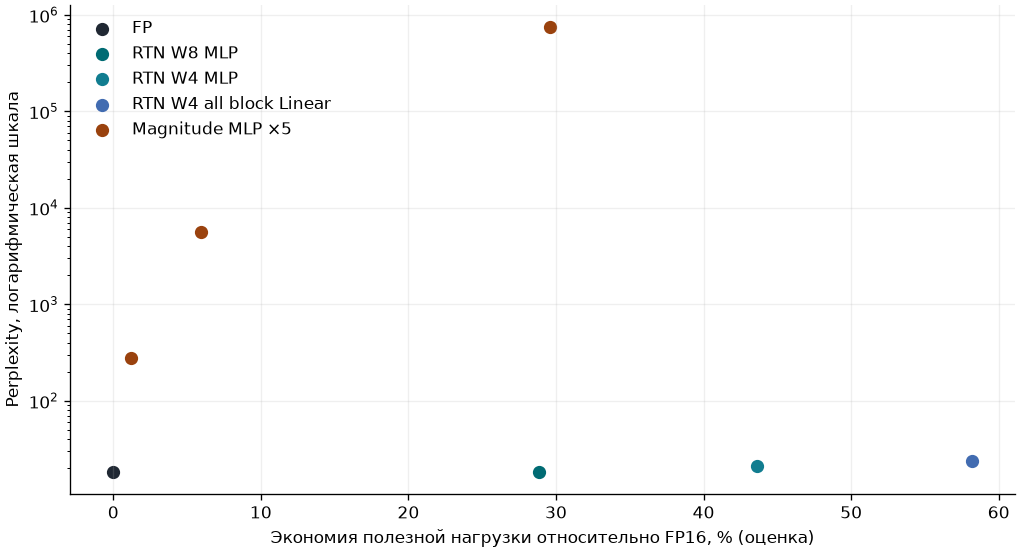

In [6]:
colors = {'FP32': '#202833', 'FP': '#202833', 'PTQ': '#006b73', 'LAMP one-shot': '#9a420e', 'LAMP iterative': '#956014', 'LAMP iterative + FT': '#6344a3', 'Dense + FT': '#536477', 'Magnitude MLP ×5': '#9a420e', 'RTN W8 MLP': '#006b73', 'RTN W4 MLP': '#117d90', 'RTN W4 all block Linear': '#426cb1'}
fig, ax = plt.subplots(figsize=(8.5, 4.6), layout="constrained")
for method, rows in matched.groupby("method", sort=False):
    ax.scatter(rows["saved_pct_est"], rows["ppl"], label=method, color=colors[method], s=48)
ax.set(xlabel="Экономия полезной нагрузки относительно FP16, % (оценка)",
       ylabel="Perplexity, логарифмическая шкала", yscale="log")
ax.grid(alpha=.2)
ax.legend(frameon=False, loc="upper left")
plt.show()

FP дал PPL **18.39**. При близкой оценке экономии размера RTN W8 в MLP дал **18.40** (28.9%), Magnitude без дообучения на доле 0.50 — **745,667.23** (29.6%). W4 RTN в MLP дал **21.07**, а по всем Linear блока — **23.53**. Для W4 близкой точки по полезной нагрузке в измеренной серии прунинга нет.

Из-за разных версий библиотек и GPU возможен сдвиг абсолютной PPL к старому exp04. Для сравнения PTQ с прунингом используются совместно измеренные значения из таблицы выше.

## 2. Исходные эксперименты по квантованию

**W4G128.** RTN, GPTQ и AWQ используют все Linear внутри блоков. WikiText-2 raw validation, окно 1024, шаг 512. GPTQ и AWQ усреднены по трём частично перекрывающимся калибровочным выборкам. PPL сравнивается внутри модели.

**W8A8.** SmoothQuant оценивается относительно обычного W8A8 на том же наборе. Для SmolLM2 доступны три калибровочных подмножества, для Pythia и OPT — по два. Источник чисел и условия — [D09](../quantization/research/D09/README.md).

In [7]:
w4 = pd.DataFrame([
    ("SmolLM2-135M", 15.6305, 21.5816, 19.5822, 18.0526),
    ("Pythia-160M", 26.7249, 45.4585, 34.2459, 35.5741),
    ("OPT-125M", 27.0983, 29.5852, 28.3184, 28.5295),
], columns=["model", "FP32", "RTN", "GPTQ", "AWQ"]).set_index("model")
for method in ("RTN", "GPTQ", "AWQ"):
    w4[f"{method} ΔPPL %"] = 100 * (w4[method] / w4["FP32"] - 1)
display(w4.round(4))

w8a8 = pd.DataFrame([
    ("SmolLM2-135M", 15.9855, 15.8001, 3),
    ("Pythia-160M", 27.5705, 27.3104, 2),
    ("OPT-125M", 27.4004, 27.2302, 2),
], columns=["model", "W8A8", "SmoothQuant W8A8", "calibration_subsets"]).set_index("model")
w8a8["SmoothQuant ΔPPL %"] = 100 * (w8a8["SmoothQuant W8A8"] / w8a8["W8A8"] - 1)
display(w8a8.round(4))

,FP32,RTN,GPTQ,AWQ,RTN ΔPPL %,GPTQ ΔPPL %,AWQ ΔPPL %
model,,,,,,,
SmolLM2-135M,15.6305,21.5816,19.5822,18.0526,38.0736,25.2820,15.4960
Pythia-160M,26.7249,45.4585,34.2459,35.5741,70.0979,28.1423,33.1122
OPT-125M,27.0983,29.5852,28.3184,28.5295,9.1773,4.5025,5.2815


,W8A8,SmoothQuant W8A8,calibration_subsets,SmoothQuant ΔPPL %
model,,,,
SmolLM2-135M,15.9855,15.8001,3,-1.1598
Pythia-160M,27.5705,27.3104,2,-0.9434
OPT-125M,27.4004,27.2302,2,-0.6212


## 2.1. Что проверяли в исследовательских сериях

| Серия | Гипотеза и результат |
|---|---|
| D05 · Подготовка корпуса | Зафиксированы разбиение WikiText-2 и протоколы оценки и тайминга. [Подготовка](../quantization/research/D05/scope.md) |
| D06 · Clipping | На трёх участках SmolLM2 локальный поиск по MSE выхода устойчиво обошёл p99.9 на двух. На третьем результат зависел от калибровки. |
| D07 · Порог по logits | Средний ΔNLL −0,01286, 15 выигрышей из 24 при пороге 16. Худшее ухудшение +0,04677 превысило допуск +0,02. |
| D08 · Переход к полным моделям | Проверены основы weight-only PTQ, работа GPTQ, состав квантованных слоёв, чувствительность к калибровке и короткие PPL-прогоны. [D08](../quantization/research/D08/README.md) |
| D10 · Форма W4-сетки | На SmolLM2 условная LUT дала PPL 17,9164 против 18,0526 у AWQ и 17,8060 у более свободной LUT. Отражаемая сетка дала 17,6886 против 17,5488 у trellis. |
| D11–D12 · Сильные контроли | На OPT отражаемая сетка в среднем улучшила PPL GPTQ на 0,74%, а свободную сетку обошла в одном из трёх сравнений. Совместная правка MLP уступила identity-контролю примерно на 1,9% на резервной калибровке. |
| D12 · Полный пакет | На development перераспределение бюджета между кодами и группами снизило PPL с 23,1521 до 20,8594 при 73 010 643 байтах. Итоговая серия не прошла совокупность критериев качества, сильных контролей и бюджета. |

Опыты используют разные наборы, охват или форматы. Числа приведены внутри их протоколов.

[Сводный отчёт](../quantization/research/quantization_results.md) · [Порог по logits](../quantization/research/D07/pilot_decision.md) · [Сетки](../quantization/research/D10/README.md) · [Поиск кодов и MLP](../quantization/research/D11/README.md)

## 3. Исходные эксперименты по прунингу

SmolLM-135M FP16, WikiText-2 test, итеративное удаление каналов MLP. Для LAMP и Taylor с LoRA за общий ориентир берётся незатронутый FP16 из того же эксперимента. В этом наборе отсутствует непрореженный LoRA-контроль. Сравнение Magnitude и LAMP на одной доле меняет одновременно критерий важности и режим обучения.

Источники — [Magnitude](../pruning/logs/llm_pruning/ppl_memory.csv), [LAMP + LoRA](../pruning/logs/llm_pruning/improved_lamp_lora.csv), [Taylor + LoRA](../pruning/logs/llm_pruning/improved_taylor_lora.csv).

In [8]:
logs = root / "pruning/logs/llm_pruning"
files = {
    "Magnitude": "ppl_memory.csv",
    "LAMP + LoRA": "improved_lamp_lora.csv",
    "Taylor + LoRA": "improved_taylor_lora.csv",
}
irina = pd.concat([pd.read_csv(logs / filename).assign(method=method)
                   for method, filename in files.items()], ignore_index=True)
fp = irina.loc[irina["method"].eq("Magnitude") & irina["ratio"].eq(0)].iloc[0]
irina["delta_ppl_pct"] = 100 * (irina["ppl"] / fp["ppl"] - 1)
irina["removed_params_pct"] = 100 * (1 - irina["params"] / fp["params"])
display(irina[["method", "ratio", "params", "removed_params_pct", "model_size_mb",
               "ppl", "delta_ppl_pct", "peak_mem_mb", "eval_time_s"]].round(3))

,method,ratio,params,removed_params_pct,model_size_mb,ppl,delta_ppl_pct,peak_mem_mb,eval_time_s
0,Magnitude,0.00,134515008,0.000,256.567,18.376,0.000,578.695,13.696
1,Magnitude,0.10,126552384,5.920,241.380,5893.113,31969.002,726.379,14.031
2,Magnitude,0.20,118588032,11.840,226.189,17030.412,92575.694,706.999,13.803
3,Magnitude,0.30,110625408,17.760,211.001,21169.498,115099.675,694.815,14.132
4,Magnitude,0.40,102664512,23.678,195.817,314822.188,1713091.945,1049.628,14.005
5,Magnitude,0.50,94701888,29.598,180.630,828641.938,4509184.125,666.709,14.148
6,LAMP + LoRA,0.02,132921792,1.184,253.528,21.979,19.604,1763.952,13.998
7,LAMP + LoRA,0.05,130533696,2.960,248.973,25.406,38.254,1772.946,14.170
8,LAMP + LoRA,0.10,126552384,5.920,241.380,31.789,72.986,1771.806,13.902
9,Taylor + LoRA,0.02,132921792,1.184,253.528,22.134,20.447,986.269,13.931


## 4. Степень эквивалентности

| Критерий | Исходный PTQ ↔ прунинг | Общий прогон |
|---|---|---|
| Модель и токенизатор | SmolLM2, Pythia, OPT ↔ SmolLM | Один SmolLM-135M, один токенизатор |
| Данные и PPL | Validation, окно 1024/512 ↔ test, окно 512/256 | Один test, окно 512/256, одна формула |
| Охват | Все Linear блоков ↔ MLP | W8/W4 MLP ↔ прунинг MLP. W4 всех Linear — контроль охвата |
| Дообучение | Без дообучения ↔ серии с LoRA и без неё | Все общие прогоны без дообучения |
| Размер и скорость | Разные реализации и учёт ресурсов | Сопоставимая оценка нагрузки FP16, фактический файл и latency INT4/INT8 вне замера |

Результат общего прогона относится к RTN и Magnitude, одному чекпойнту и одному тесту. GPTQ, AWQ, LAMP и Taylor + LoRA по-прежнему представлены исходными экспериментами.